# 03 – Case study: Mannheim, 12 months of 2021

The prototype is run for the city of **Mannheim** (Germany) with exactly the code of the web app (`prototype/app.py`).
Mannheim is not part of the training, validation or test data (all project areas are at least 50 km away).

1. **12 monthly maps** with the final setting (*ensemble*: the setting chosen on the validation set in 02c) and,
   for comparison, with the standard mode (SegFormer-B3 alone).
2. **Predicted class shares per month, month-to-month change and total change** in percentage points (pp).
3. **Comparison with two reference maps**, on the pixels that the shares are calculated on:
   - **Dynamic World** (monthly, from Sentinel-2 optical images): an external reference, never used for training or
     as model input.
   - **ESA WorldCover 2021** (annual): the product the training labels come from, here evaluated at a place that was
     not used for training. It is therefore not fully independent of the model.
4. **Is a predicted change real or noise?** Every pixel is classified as *stable*, *persistent predicted transition*
   (one change, at least three months with the old and three with the new class) or *other transitions* (no persistent
   pattern). Persistent predicted transitions are checked against Dynamic World.
5. **Seasonal radar effect:** built-up in January vs. vegetation in July.

All results are saved in `data/prototype_results/mannheim_case_study/`.

# 1. Setup

In [1]:
import sys
import subprocess
import importlib
import warnings

# google-api-core warns about a grpcio version in 2027 - not relevant here
warnings.filterwarnings("ignore", category=FutureWarning, module="google.api_core")


def pip_install(*arguments):
    # quiet install; pip's notes about other packages on the JupyterHub are only shown if the install fails
    result = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *arguments],
                            capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout[-3000:], result.stderr[-3000:])
        raise RuntimeError("pip install failed: " + " ".join(arguments))


# the prototype packages (versions as in requirements.txt); TensorFlow, Keras, NumPy, pandas and matplotlib
# are already installed on the JupyterHub
pip_install("earthengine-api==1.7.49", "rasterio==1.4.4", "gradio==6.31.0")
importlib.invalidate_caches()          # lets Python find packages that were installed just now
for module in ["ee", "rasterio", "gradio"]:
    importlib.import_module(module)
print("packages ready")

packages ready


In [2]:
import tensorflow as tf

# take GPU memory only when it is needed, so this notebook also runs while another notebook holds some of it
# (must run before the first model is loaded; after a kernel restart this cell has to come first)
try:
    for gpu in tf.config.list_physical_devices("GPU"):
        tf.config.experimental.set_memory_growth(gpu, True)
    print("GPUs:", tf.config.list_physical_devices("GPU"))
except RuntimeError:
    print("the GPU was already in use in this kernel - restart the kernel and run all cells from the top")

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from importlib.metadata import version as package_version, PackageNotFoundError

# keras-hub (SegFormer) is installed WITHOUT its dependencies: its metadata asks for tensorflow-text, which would
# replace the installed TensorFlow. keras-hub 0.24.0 works with Keras 3.8 - 3.14 (tested: TensorFlow 2.20, Keras 3.11.2).
KERAS_HUB = "0.24.0"
try:
    installed = package_version("keras-hub")
except PackageNotFoundError:
    installed = None
if installed != KERAS_HUB:
    print(f"installing keras-hub {KERAS_HUB} (found: {installed})")
    pip_install("--no-deps", "--force-reinstall", f"keras-hub=={KERAS_HUB}")
    if "keras_hub" in sys.modules:
        raise RuntimeError("keras-hub was replaced - restart the kernel and run all cells again")

# small packages keras-hub needs (they do not depend on TensorFlow)
missing = []
for package in ["kagglehub", "huggingface_hub", "regex", "rich"]:
    try:
        package_version(package.replace("_", "-"))
    except PackageNotFoundError:
        missing.append(package)
if missing:
    pip_install(*missing)

import keras_hub
print("keras-hub:", keras_hub.__version__)

installing keras-hub 0.24.0 (found: None)
keras-hub: 0.24.0


In [4]:
import ee

PROJECT_ID = "sentinel1-lulc-project-512618"

# Only asks for a new login when the saved token is missing. Clear this cell's output before sharing.
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate(auth_mode="notebook")
    ee.Initialize(project=PROJECT_ID)
print("Earth Engine ready:", ee.Number(1).getInfo())


Successfully saved authorization token.
Earth Engine ready: 1


In [6]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display, Markdown

sys.path.insert(0, "prototype")
import app
import lulc_core
from lulc_core import IGNORE, NODATA

LAT, LON = 49.4875, 8.4660          # Mannheim city centre
START_YEAR, START_MONTH = "2021", "January"
SIZE_KM = 10

app.MODEL_DIR = "models/round3"
app.PROJECT_ID = PROJECT_ID
output = Path("data/prototype_results/mannheim_case_study")
output.mkdir(parents=True, exist_ok=True)

# 2. Twelve monthly maps with the final setting

The same function as behind the web app's button. The Dynamic World comparison of the app is switched on.

**Track:** ascending orbit 15 (same viewing geometry and pixel grid in all months; chosen by number of months, coverage of the area and number of scenes)

**Scenes per month:** 5, 4, 5, 5, 5, 5, 6, 5, 5, 5, 5, 5

**Counted area:** 101.2 km² (100.0% of the image). Only pixels with radar data in every available month are counted, so missing coverage cannot look like change. All shares and changes refer to this area (saved as common_valid_area.tif).

**Model:** ensemble of 4 models (segformer_b3, segformer_b2, deeplabv3plus_resnet50, unet_resnet50), 8 flips/rotations each (test mIoU 0.432 on the six test areas)

**Prediction time:** 108 s for 12 maps

The tables show **predicted** land cover and **predicted** changes in percentage points. Month-to-month changes of a few points can be caused by seasonal radar effects (leaves, soil moisture, frost) and by model errors, not only by real land cover change.

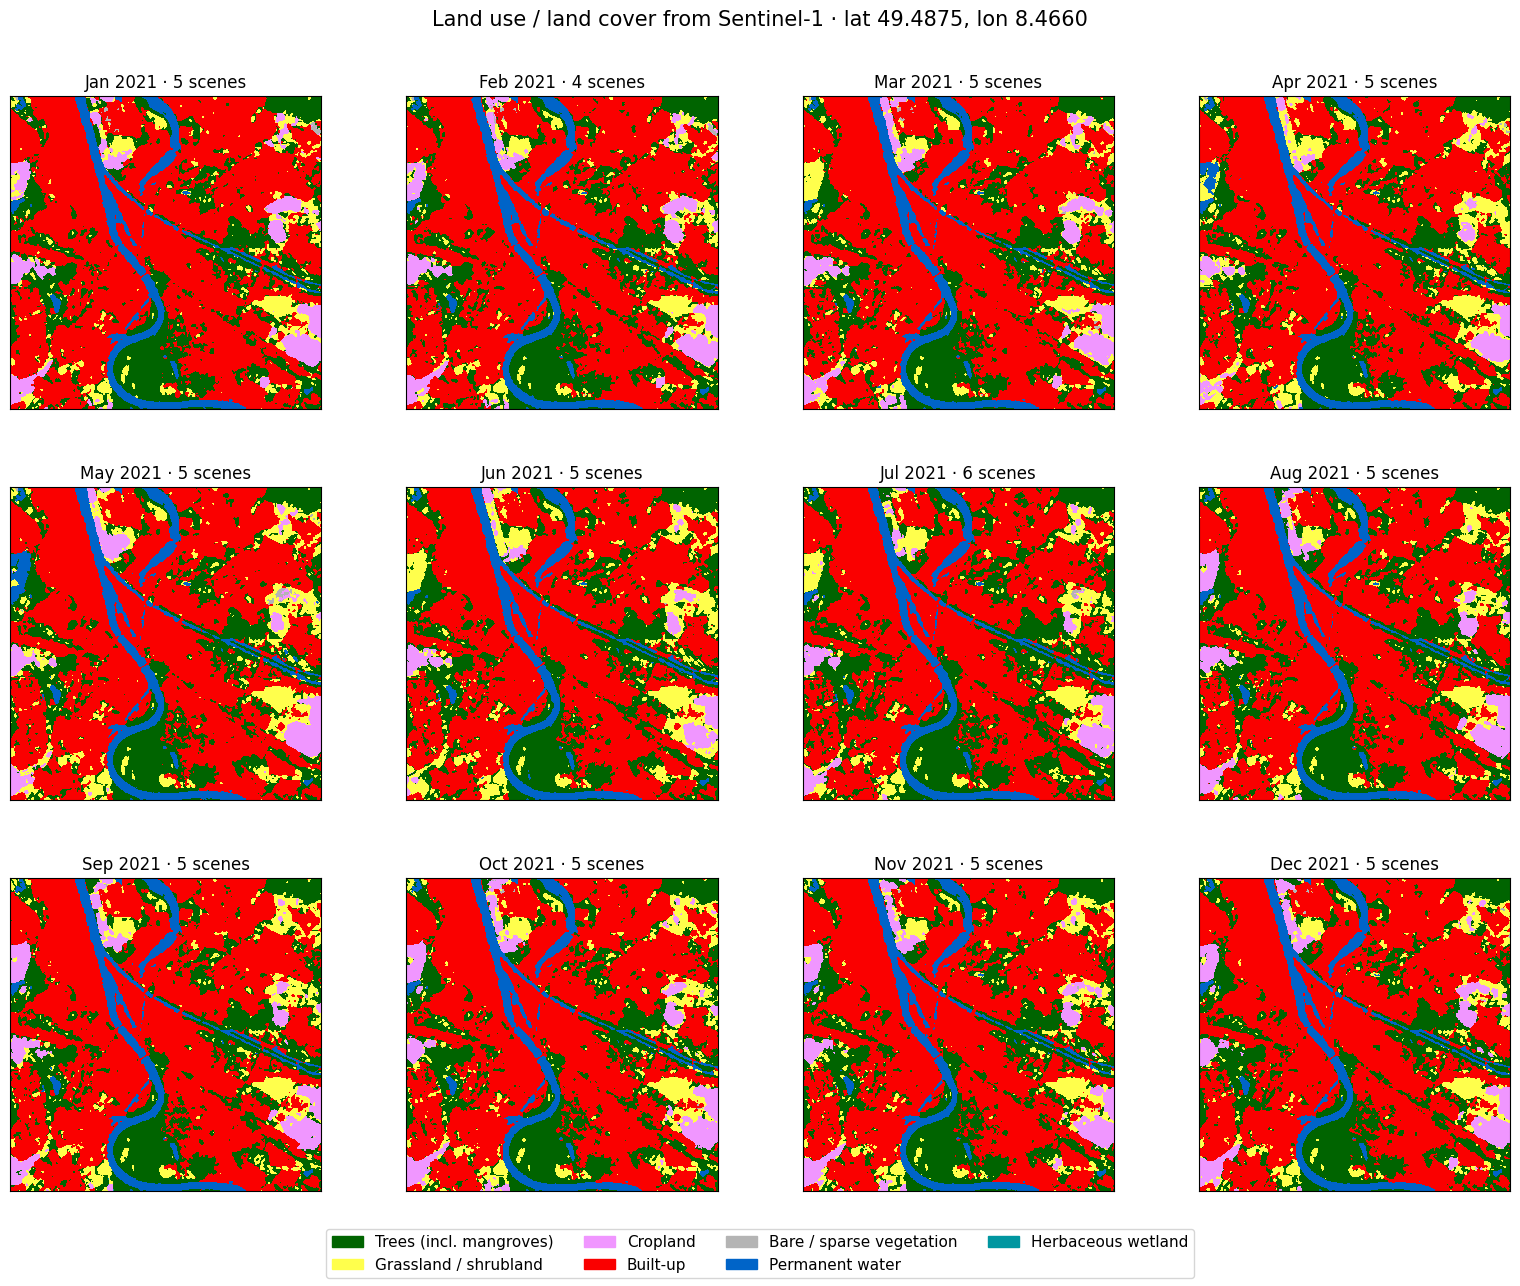

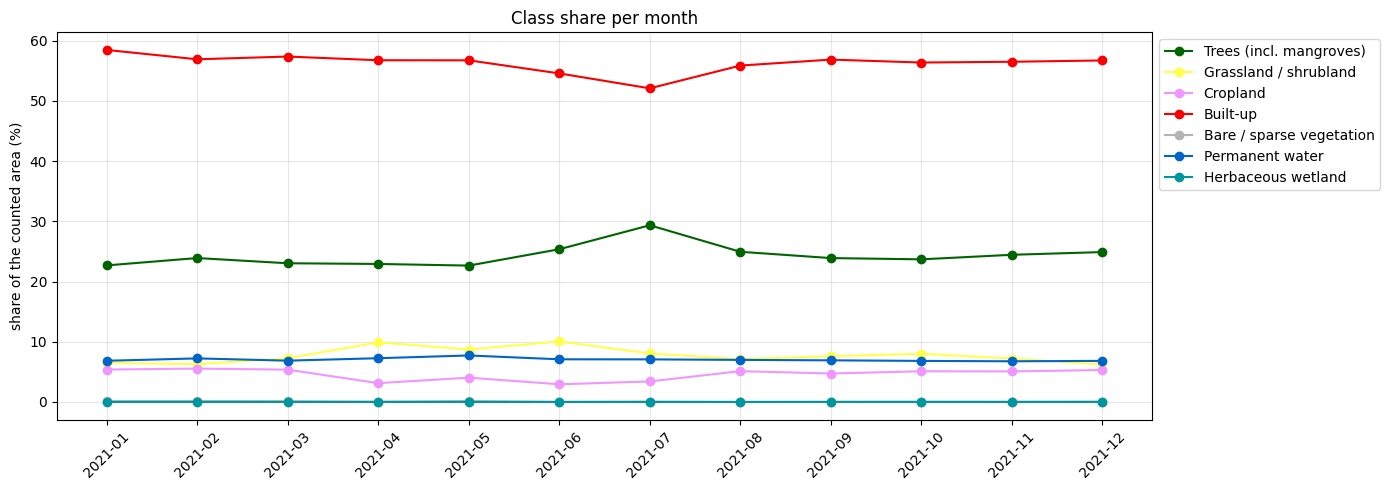

In [7]:
outputs, run_ensemble = app.run_with_record(LAT, LON, START_YEAR, START_MONTH, SIZE_KM, True, "ensemble")
(summary, map_figure, share_figure, share_table, change_table, total_table, dw_table, files) = outputs

display(Markdown(summary))
display(map_figure)
display(share_figure)
plt.close("all")

## Predicted class share per month (%)

In [8]:
display(share_table)

,month,Trees (incl. mangroves),Grassland / shrubland,Cropland,Built-up,Bare / sparse vegetation,Permanent water,Herbaceous wetland
0,2021-01,22.68,6.51,5.38,58.46,0.14,6.84,0.00
1,2021-02,23.90,6.27,5.54,56.91,0.16,7.23,0.00
2,2021-03,23.03,7.26,5.36,57.36,0.13,6.85,0.00
3,2021-04,22.92,9.90,3.12,56.75,0.05,7.26,0.00
4,2021-05,22.64,8.71,4.03,56.74,0.16,7.72,0.00
5,2021-06,25.36,10.05,2.93,54.56,0.01,7.08,0.00
6,2021-07,29.34,8.05,3.40,52.08,0.05,7.07,0.00
7,2021-08,24.94,7.11,5.11,55.86,0.00,6.98,0.00
8,2021-09,23.89,7.60,4.72,56.86,0.01,6.91,0.01
9,2021-10,23.68,8.00,5.09,56.37,0.04,6.81,0.00


## Predicted month-to-month change (percentage points)

In [9]:
display(change_table)

,change,Trees (incl. mangroves),Grassland / shrubland,Cropland,Built-up,Bare / sparse vegetation,Permanent water,Herbaceous wetland
0,2021-01 → 2021-02,1.22,-0.24,0.16,-1.56,0.02,0.39,0.00
1,2021-02 → 2021-03,-0.87,0.99,-0.18,0.46,-0.03,-0.38,0.00
2,2021-03 → 2021-04,-0.12,2.64,-2.24,-0.61,-0.08,0.41,0.00
3,2021-04 → 2021-05,-0.27,-1.19,0.92,-0.01,0.11,0.46,0.00
4,2021-05 → 2021-06,2.72,1.34,-1.10,-2.17,-0.14,-0.64,-0.00
5,2021-06 → 2021-07,3.98,-2.00,0.47,-2.48,0.04,-0.01,0.00
6,2021-07 → 2021-08,-4.40,-0.94,1.71,3.78,-0.05,-0.09,0.00
7,2021-08 → 2021-09,-1.05,0.49,-0.39,0.99,0.01,-0.07,0.01
8,2021-09 → 2021-10,-0.21,0.40,0.37,-0.49,0.03,-0.09,-0.01
9,2021-10 → 2021-11,0.75,-0.78,-0.02,0.13,-0.01,-0.06,0.00


## Predicted total change, first to last month (percentage points)

In [10]:
display(total_table)

,change,Trees (incl. mangroves),Grassland / shrubland,Cropland,Built-up,Bare / sparse vegetation,Permanent water,Herbaceous wetland
0,2021-01 → 2021-12,2.21,-0.29,-0.08,-1.75,-0.08,-0.02,0.0


## Comparison with Dynamic World as shown in the app

On the counted pixels, in each month only where Dynamic World has a cloud-free label.

In [11]:
display(dw_table)

,month,status,compared area %,agreement %,Trees (incl. mangroves): model %,Trees (incl. mangroves): Dynamic World %,Grassland / shrubland: model %,Grassland / shrubland: Dynamic World %,Cropland: model %,Cropland: Dynamic World %,Built-up: model %,Built-up: Dynamic World %,Bare / sparse vegetation: model %,Bare / sparse vegetation: Dynamic World %,Permanent water: model %,Permanent water: Dynamic World %,Herbaceous wetland: model %,Herbaceous wetland: Dynamic World %
0,2021-01,ok,22.8,65.2,16.1,9.7,3.5,5.3,2.5,2.4,66.6,50.4,0.2,16.5,11.0,15.7,0.0,0.0
1,2021-02,ok,100.0,74.4,23.9,6.2,6.3,3.2,5.5,9.4,56.9,72.3,0.2,1.0,7.2,8.0,0.0,0.0
2,2021-03,ok,100.0,74.5,23.0,5.9,7.3,2.9,5.4,8.2,57.4,75.3,0.1,0.3,6.9,7.5,0.0,0.0
3,2021-04,ok,43.1,70.6,19.0,2.9,11.4,1.5,3.1,9.7,60.6,79.5,0.0,1.0,5.8,5.4,0.0,0.0
4,2021-05,ok,20.0,67.8,27.7,5.0,6.7,1.4,3.4,7.2,57.9,82.9,0.1,0.0,4.2,3.4,0.0,0.0
5,2021-06,ok,100.0,70.7,25.4,7.3,10.1,1.7,2.9,9.3,54.6,74.0,0.0,0.5,7.1,7.2,0.0,0.0
6,2021-07,ok,100.0,69.6,29.3,8.2,8.0,1.3,3.4,9.4,52.1,72.5,0.1,0.2,7.1,8.2,0.0,0.2
7,2021-08,no pixel valid in both maps,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2021-09,ok,100.0,76.4,23.9,9.8,7.6,1.7,4.7,8.1,56.9,73.1,0.0,0.2,6.9,7.1,0.0,0.0
9,2021-10,no pixel valid in both maps,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Standard mode (SegFormer-B3 alone) for comparison

Same downloads (from the cache), only the model setting differs.

In [12]:
outputs_std, run_standard = app.run_with_record(LAT, LON, START_YEAR, START_MONTH, SIZE_KM, False, "standard")
share_std, total_std = outputs_std[3], outputs_std[5]
plt.close("all")

classes = share_table.columns[1:].tolist()
modes = pd.DataFrame({
    "mean share, ensemble %": share_table[classes].mean(),
    "mean share, standard %": share_std[classes].mean(),
    "total change, ensemble pp": total_table[classes].iloc[0],
    "total change, standard pp": total_std[classes].iloc[0],
}).round(2)
display(modes)
print(f"prediction time: ensemble {run_ensemble['prediction_seconds']:.0f} s, "
      f"standard {run_standard['prediction_seconds']:.0f} s for {run_ensemble['months_with_map']} maps")
modes.to_csv(output / "ensemble_vs_standard.csv")

,"mean share, ensemble %","mean share, standard %","total change, ensemble pp","total change, standard pp"
Trees (incl. mangroves),24.31,24.51,2.21,1.92
Grassland / shrubland,7.74,7.15,-0.29,-0.83
Cropland,4.59,5.01,-0.08,0.78
Built-up,56.26,55.65,-1.75,-1.76
Bare / sparse vegetation,0.07,0.28,-0.08,-0.06
Permanent water,7.03,7.40,-0.02,-0.06
Herbaceous wetland,0.00,0.01,0.00,0.00


prediction time: ensemble 108 s, standard 31 s for 12 maps


# 3. Comparison with Dynamic World and WorldCover on the counted pixels

Only pixels that are counted in the shares (radar in every month, `common_valid_area.tif`) are compared, and in each
reference only pixels with a valid label (Dynamic World: no clouds in that month; WorldCover: not snow / no data).

In [13]:
info = json.loads((Path(app.MODEL_DIR) / "model_info.json").read_text())
CLASSES, COLORS = info["classes"], info["colors"]
N_CLASSES = len(CLASSES)
cmap = ListedColormap(COLORS)
legend = [Patch(color=c, label=n) for c, n in zip(COLORS, CLASSES)]

result_folder = Path(run_ensemble["result_folder"])
labels = run_ensemble["months"]
grid = {**run_ensemble["grid"], "folder": run_ensemble["cache_folder"]}


def read_map(path):
    with rasterio.open(path) as src:
        return src.read(1)


# only the months that this run produced (the app clears the folder before every run)
maps = [None if label in run_ensemble["missing_months"] else read_map(result_folder / f"lulc_{label}.tif")
        for label in labels]
common = read_map(result_folder / "common_valid_area.tif") == 1
print(f"{sum(m is not None for m in maps)} maps, counted area {common.mean() * 100:.1f} % of the image")

worldcover = lulc_core.fetch_worldcover(grid)
dynamic_world = []
for label in labels:
    year, month = map(int, label.split("-"))
    try:
        dynamic_world.append(lulc_core.fetch_dynamic_world(LAT, LON, year, month, grid, int(SIZE_KM * 500)))
    except Exception as error:
        print(f"{label}: Dynamic World not available ({error})")
        dynamic_world.append(None)


def on_counted_pixels(class_map):
    return np.where(common, class_map, IGNORE).astype(np.uint8)


rows, iou_dw, iou_wc = [], [], []
for label, class_map, dw in zip(labels, maps, dynamic_world):
    row = {"month": label}
    if class_map is None:
        rows.append(row)
        continue
    prediction = on_counted_pixels(class_map)
    for name, reference, store in [("Dynamic World", dw, iou_dw), ("WorldCover 2021", worldcover, iou_wc)]:
        result = None if reference is None else lulc_core.compare_maps(prediction, reference, N_CLASSES)
        if result is None:
            continue
        row[f"{name}: compared %"] = 100 * result["compared_fraction"]
        row[f"{name}: agreement %"] = 100 * result["agreement"]
        store.append(result["iou"])
    rows.append(row)

agreement = pd.DataFrame(rows).set_index("month").round(1)
display(agreement)
agreement.to_csv(output / "agreement_per_month.csv")

import warnings
with warnings.catch_warnings():          # a class that is absent in all months gives NaN
    warnings.simplefilter("ignore", RuntimeWarning)
    iou_table = pd.DataFrame({"IoU vs Dynamic World (mean over months)": np.nanmean(iou_dw, axis=0),
                              "IoU vs WorldCover 2021 (mean over months)": np.nanmean(iou_wc, axis=0)},
                             index=CLASSES).round(3)
display(iou_table)
iou_table.to_csv(output / "iou_per_class.csv")

12 maps, counted area 100.0 % of the image


,Dynamic World: compared %,Dynamic World: agreement %,WorldCover 2021: compared %,WorldCover 2021: agreement %
month,,,,
2021-01,22.8,65.2,100.0,76.7
2021-02,100.0,74.4,100.0,76.8
2021-03,100.0,74.5,100.0,76.5
2021-04,43.1,70.6,100.0,75.4
2021-05,20.0,67.8,100.0,75.3
2021-06,100.0,70.7,100.0,74.4
2021-07,100.0,69.6,100.0,74.3
2021-08,NaN,NaN,100.0,76.0
2021-09,100.0,76.4,100.0,76.1


,IoU vs Dynamic World (mean over months),IoU vs WorldCover 2021 (mean over months)
Trees (incl. mangroves),0.252,0.493
Grassland / shrubland,0.152,0.317
Cropland,0.367,0.531
Built-up,0.713,0.720
Bare / sparse vegetation,0.021,0.031
Permanent water,0.746,0.800
Herbaceous wetland,0.000,0.000


## Class shares of the model and of both references, per month

In every month, the model, Dynamic World and WorldCover are compared on **the same pixels**: counted pixels where
Dynamic World has a cloud-free label and WorldCover has a label. The compared footprint therefore changes from month
to month (column `compared %`); months without usable Dynamic World pixels are left out of this comparison.
The predicted shares of the whole counted area (the app's main result) are in the tables of section 2.

month,2021-01,2021-02,2021-03,2021-04,2021-05,2021-06,2021-07,2021-09
compared %,22.83,99.96,99.98,43.07,19.96,99.99,100.0,100.0


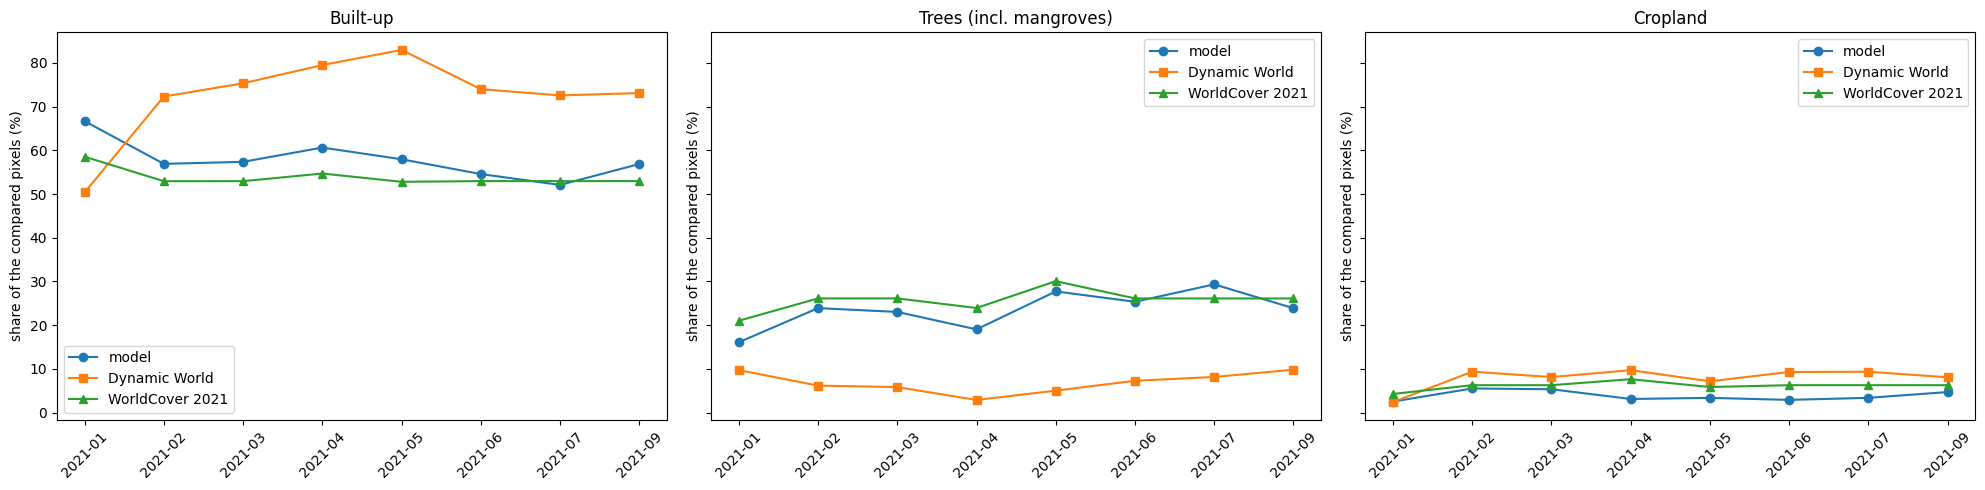

In [14]:
share_rows = []
for label, class_map, dw in zip(labels, maps, dynamic_world):
    if class_map is None or dw is None:
        continue
    valid = common & (class_map != IGNORE) & (worldcover != IGNORE) & (dw != IGNORE)
    if not valid.any():          # e.g. a month in which Dynamic World has no cloud-free pixel
        continue
    for name, source in [("model", class_map), ("Dynamic World", dw), ("WorldCover 2021", worldcover)]:
        share_rows.append({"month": label, "map": name, "compared %": 100 * valid.mean(),
                           **{c: 100 * np.mean(source[valid] == k) for k, c in enumerate(CLASSES)}})
shares_all = pd.DataFrame(share_rows).round(2)
display(shares_all[shares_all["map"] == "model"][["month", "compared %"]].set_index("month").T)
shares_all.to_csv(output / "shares_model_and_references.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, name in zip(axes, ["Built-up", "Trees (incl. mangroves)", "Cropland"]):
    for source, marker in [("model", "o"), ("Dynamic World", "s"), ("WorldCover 2021", "^")]:
        part = shares_all[shares_all["map"] == source]
        ax.plot(part["month"], part[name], marker=marker, label=source)
    ax.set_title(name)
    ax.set_ylabel("share of the compared pixels (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.savefig(output / "shares_model_and_references.png", dpi=150)
plt.show()

## Side by side: January and July

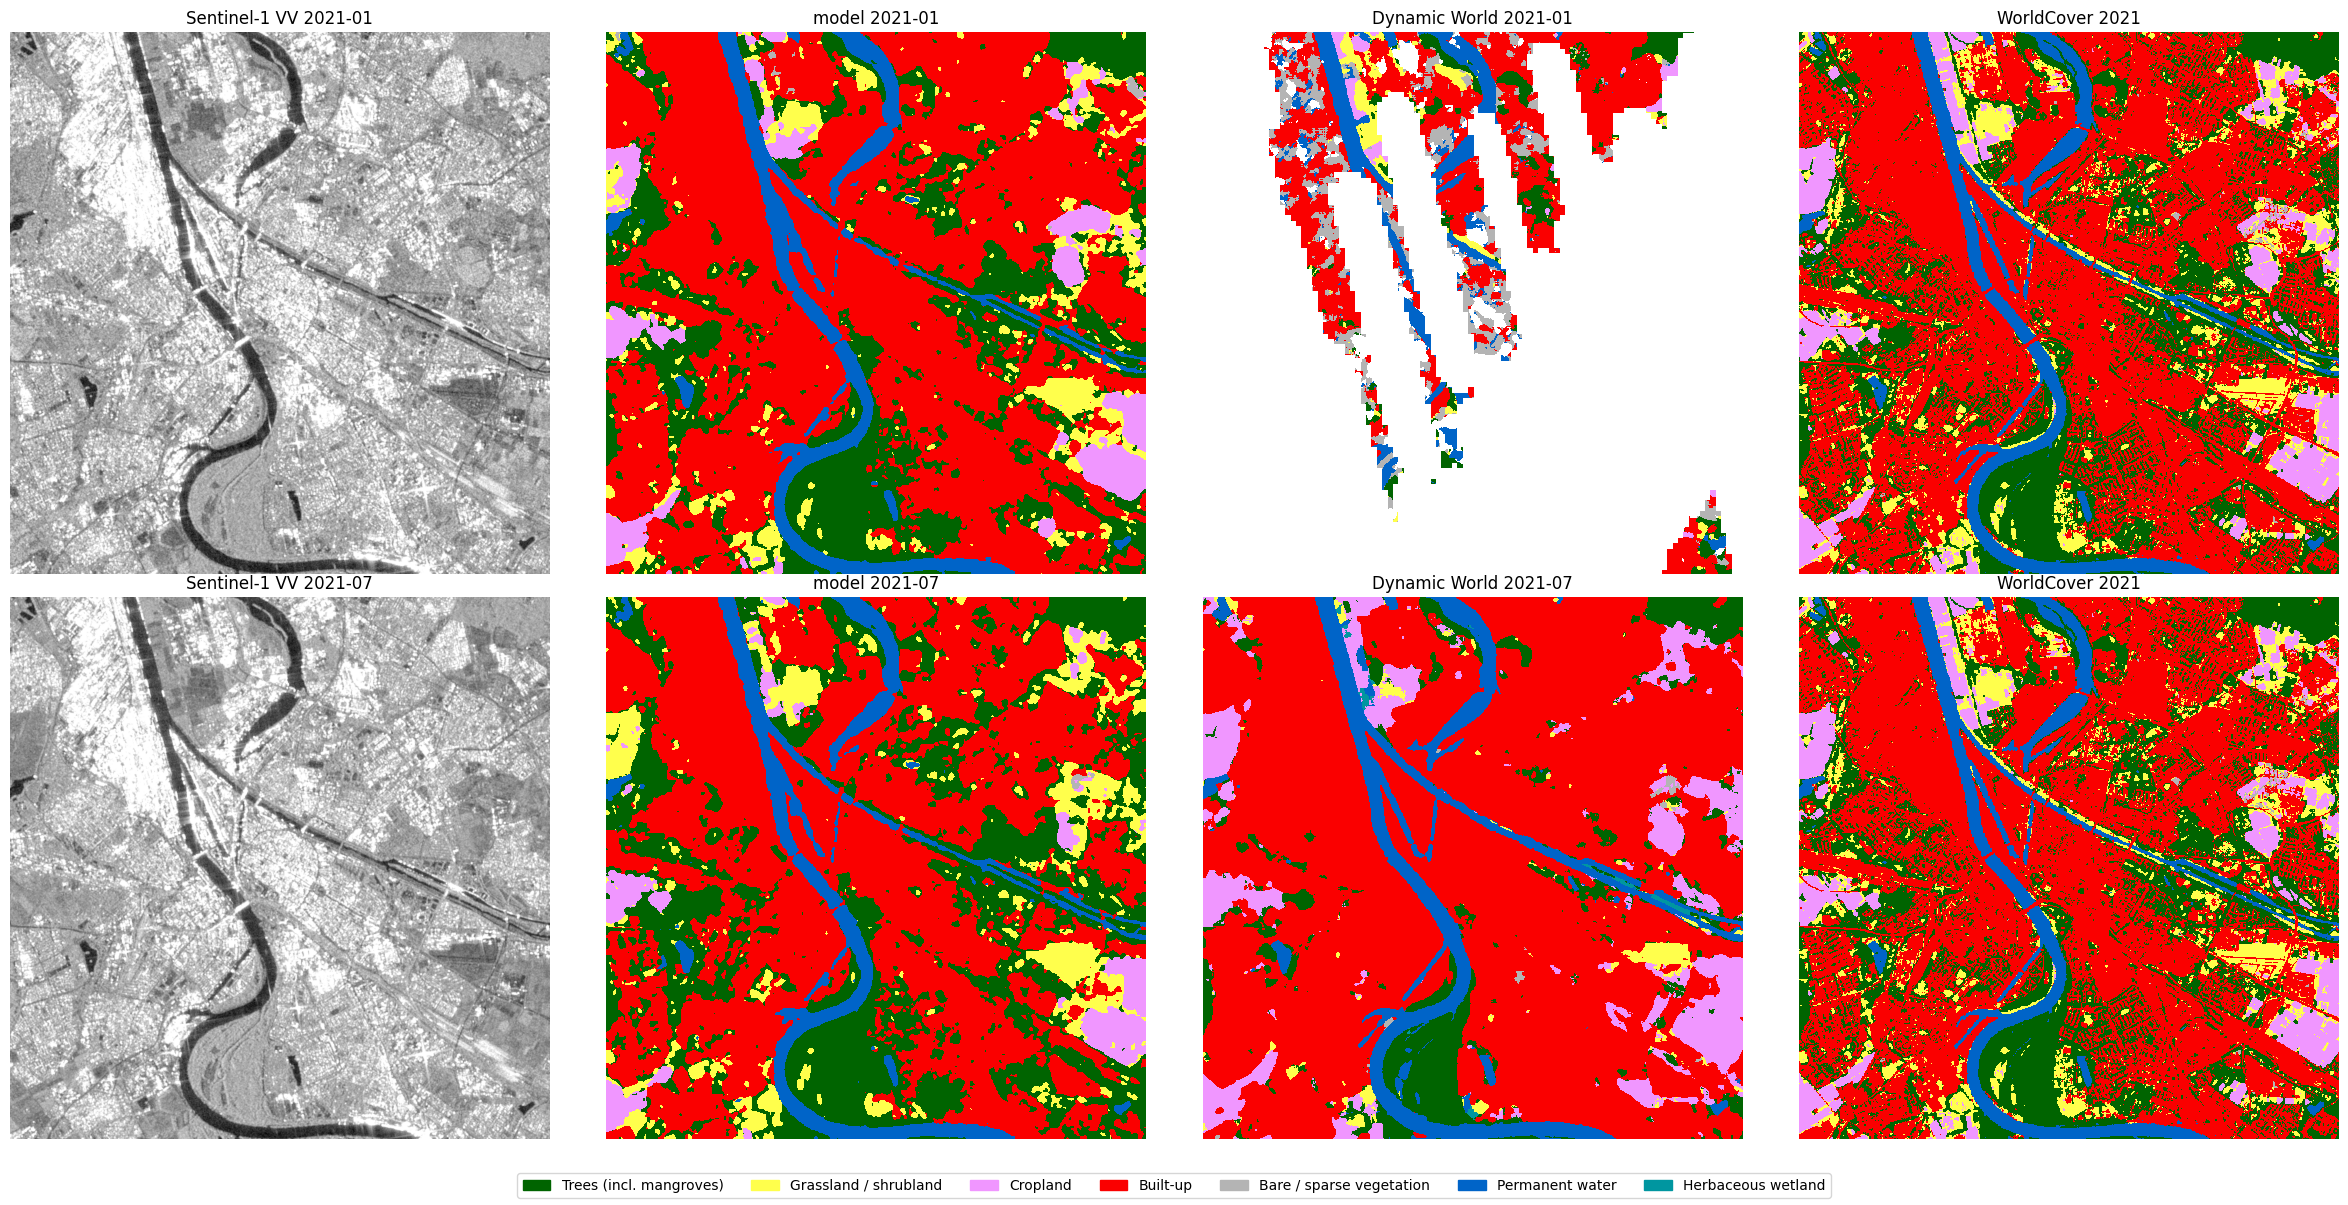

In [15]:
def show_classes(ax, class_map, title):
    ax.imshow(np.ma.masked_equal(class_map, IGNORE), cmap=cmap, vmin=-0.5, vmax=N_CLASSES - 0.5, interpolation="nearest")
    ax.set_title(title)


months_cache = Path(run_ensemble["cache_folder"])
fig, axes = plt.subplots(2, 4, figsize=(24, 12))
for row, label in zip(axes, [labels[0], labels[6]]):
    i = labels.index(label)
    radar_path = months_cache / f"s1_{label.replace('-', '_')}.tif"
    if radar_path.exists():
        vv = lulc_core.read_radar(radar_path)[0]
        row[0].imshow(np.where(vv == NODATA, np.nan, vv), cmap="gray", vmin=-25, vmax=0)
    row[0].set_title(f"Sentinel-1 VV {label}")
    show_classes(row[1], on_counted_pixels(maps[i]), f"model {label}")
    if dynamic_world[i] is not None:
        show_classes(row[2], dynamic_world[i], f"Dynamic World {label}")
    row[2].set_title(f"Dynamic World {label}")
    show_classes(row[3], worldcover, "WorldCover 2021")
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=legend, loc="lower center", ncol=N_CLASSES)
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig(output / "side_by_side_january_july.png", dpi=120)
plt.show()

# 4. Persistent predicted transitions

A month-to-month difference in the shares can come from real change, from seasonal radar effects or from model
errors. For every counted pixel, the sequence of its predicted classes over the months with a map is checked:

| status | rule |
|---|---|
| stable | the same class in every month with a map |
| persistent predicted transition | exactly one change; the old class in at least 3 months before it, the new class in at least 3 months from it on |
| other transitions (no persistent pattern) | anything else: changes back and forth, or a class seen in fewer than 3 months |

Months without a map are skipped. If such a gap lies directly before the first month with the new class, the change
can only be dated to the gap; these pixels are counted separately (`change inside a data gap`).

Each persistent predicted transition is checked against Dynamic World **around the month of the change**: for every
pixel, the last month before the change and the first month from the change on in which Dynamic World has a valid
(cloud-free) label are used. The transition is

- **supported** if Dynamic World shows the old class before and the new class after,
- **not seen by Dynamic World** if Dynamic World shows the same class before and after,
- otherwise neither (Dynamic World shows other classes).

This is supporting evidence, not proof: Dynamic World is a model too.

,status,share of counted area %
0,stable,73.54
1,persistent predicted transition,0.55
2,other transitions (no persistent pattern),25.91


months without a map: none; persistent transitions with the change inside a data gap: 0
persistent predicted transitions checkable with Dynamic World: 4,622 of 5,519 pixels; supported 0.8 %, not seen by Dynamic World 90.2 %


,from,to,pixels,share of counted area %,checkable with Dynamic World,supported by Dynamic World %,not seen by Dynamic World %
11,Built-up,Trees (incl. mangroves),1709,0.17,1512,0.13,97.75
9,Cropland,Grassland / shrubland,1199,0.12,1184,0.84,80.57
2,Trees (incl. mangroves),Built-up,652,0.06,418,0.00,94.74
6,Grassland / shrubland,Built-up,498,0.05,371,0.00,99.73
8,Cropland,Trees (incl. mangroves),396,0.04,211,1.42,93.84
4,Grassland / shrubland,Trees (incl. mangroves),340,0.03,339,4.72,74.34
12,Built-up,Grassland / shrubland,280,0.03,266,0.00,96.24
0,Trees (incl. mangroves),Grassland / shrubland,162,0.02,134,0.00,66.42
5,Grassland / shrubland,Cropland,122,0.01,65,3.08,93.85
13,Built-up,Permanent water,51,0.01,36,5.56,91.67


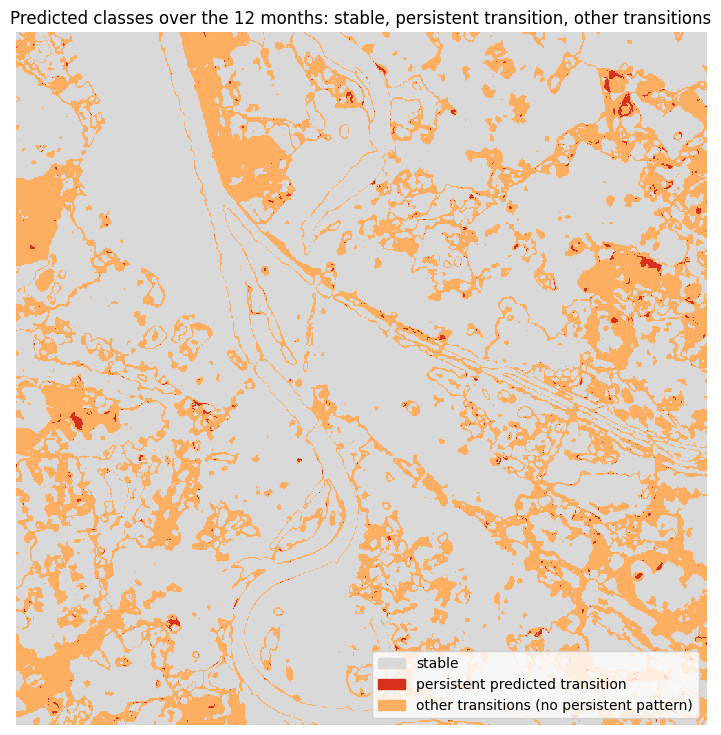

In [16]:
MIN_MONTHS = 3
available = [i for i, m in enumerate(maps) if m is not None]
stack = np.stack([maps[i] for i in available])[:, common]         # (months, counted pixels)

changes_count = (np.diff(stack, axis=0) != 0).sum(axis=0)
first_change = np.argmax(np.diff(stack, axis=0) != 0, axis=0) + 1  # index of the first month with the new class
before_ok = first_change >= MIN_MONTHS
after_ok = len(available) - first_change >= MIN_MONTHS

PERSISTENT, OTHER = "persistent predicted transition", "other transitions (no persistent pattern)"
status = np.full(stack.shape[1], OTHER, dtype=object)
status[changes_count == 0] = "stable"
status[(changes_count == 1) & before_ok & after_ok] = PERSISTENT

summary_rows = [{"status": s, "share of counted area %": 100 * np.mean(status == s)} for s in ["stable", PERSISTENT, OTHER]]
persistence = pd.DataFrame(summary_rows).round(2)
display(persistence)
persistence.to_csv(output / "persistence.csv", index=False)

missing = [labels[i] for i in range(len(labels)) if i not in available]
lasting = status == PERSISTENT
change_at = first_change[lasting]                                   # position (in the available months) of the change
in_gap = np.array([available[f] - available[f - 1] > 1 for f in change_at], dtype=bool)
print(f"months without a map: {', '.join(missing) if missing else 'none'}; "
      f"persistent transitions with the change inside a data gap: {int(in_gap.sum())}")

# which transitions are persistent, and does Dynamic World support them?
old_class, new_class = stack[0][lasting], stack[-1][lasting]

# Dynamic World on the counted pixels, in the same months as the maps (IGNORE where it has no valid label)
no_label = np.full(int(common.sum()), IGNORE, dtype=np.uint8)
dw_stack = np.stack([dynamic_world[i][common] if dynamic_world[i] is not None else no_label for i in available])
dw_lasting = dw_stack[:, lasting]                                   # (months, lasting pixels)

dw_before = np.full(len(change_at), IGNORE, dtype=np.uint8)         # last valid label before the change
dw_after = np.full(len(change_at), IGNORE, dtype=np.uint8)          # first valid label from the change on
for f in np.unique(change_at):
    pixels = np.where(change_at == f)[0]
    before, after = dw_before[pixels], dw_after[pixels]
    for t in range(f - 1, -1, -1):
        take = (before == IGNORE) & (dw_lasting[t, pixels] != IGNORE)
        before[take] = dw_lasting[t, pixels][take]
    for t in range(f, len(available)):
        take = (after == IGNORE) & (dw_lasting[t, pixels] != IGNORE)
        after[take] = dw_lasting[t, pixels][take]
    dw_before[pixels], dw_after[pixels] = before, after
checkable = (dw_before != IGNORE) & (dw_after != IGNORE)

rows = []
for a in range(N_CLASSES):
    for b in range(N_CLASSES):
        chosen = (old_class == a) & (new_class == b)
        if chosen.sum() == 0:
            continue
        check = chosen & checkable
        rows.append({"from": CLASSES[a], "to": CLASSES[b], "pixels": int(chosen.sum()),
                     "share of counted area %": 100 * chosen.sum() / stack.shape[1],
                     "checkable with Dynamic World": int(check.sum()),
                     "supported by Dynamic World %": 100 * np.mean((dw_before[check] == a) & (dw_after[check] == b))
                                                     if check.any() else np.nan,
                     "not seen by Dynamic World %": 100 * np.mean(dw_before[check] == dw_after[check])
                                                    if check.any() else np.nan})
transitions = pd.DataFrame(rows, columns=["from", "to", "pixels", "share of counted area %",
                                          "checkable with Dynamic World", "supported by Dynamic World %",
                                          "not seen by Dynamic World %"])
if checkable.any():
    supported = (dw_before == old_class) & (dw_after == new_class) & checkable
    print(f"persistent predicted transitions checkable with Dynamic World: {checkable.sum():,} of {lasting.sum():,} pixels; "
          f"supported {100 * supported.sum() / checkable.sum():.1f} %, "
          f"not seen by Dynamic World {100 * np.sum((dw_before == dw_after) & checkable) / checkable.sum():.1f} %")
transitions = transitions.sort_values("pixels", ascending=False).round(2)
display(transitions.head(15))
transitions.to_csv(output / "persistent_transitions.csv", index=False)

status_map = np.full(common.shape, IGNORE, dtype=np.uint8)
status_map[common] = np.select([status == "stable", status == PERSISTENT], [0, 1], 2)
lulc_core.save_map(status_map, output / "persistence_map.tif", grid)

fig, ax = plt.subplots(figsize=(9, 9))
ax.imshow(np.ma.masked_equal(status_map, IGNORE), cmap=ListedColormap(["#d9d9d9", "#d7301f", "#fdae61"]),
          vmin=-0.5, vmax=2.5, interpolation="nearest")
ax.legend(handles=[Patch(color="#d9d9d9", label="stable"), Patch(color="#d7301f", label=PERSISTENT),
                   Patch(color="#fdae61", label=OTHER)], loc="lower right")
ax.set_title("Predicted classes over the 12 months: stable, persistent transition, other transitions")
ax.axis("off")
plt.savefig(output / "persistence_map.png", dpi=120)
plt.show()

# 5. Seasonal radar effect: built-up in January, vegetation in July

How much of the counted area changes from built-up (January) to a vegetation class (July) in the prediction, and what
does Dynamic World say for these pixels?

In [17]:
first, second = labels.index(f"{START_YEAR}-01"), labels.index(f"{START_YEAR}-07")
BUILT = CLASSES.index("Built-up")
GREEN = [CLASSES.index(n) for n in ["Trees (incl. mangroves)", "Grassland / shrubland", "Cropland"]]

if maps[first] is None or maps[second] is None:
    print("January or July has no map")
else:
    switched = common & (maps[first] == BUILT) & np.isin(maps[second], GREEN)
    print(f"built-up in {labels[first]} -> vegetation in {labels[second]}: "
          f"{100 * switched.sum() / common.sum():.1f} % of the counted area")
    dw_a, dw_b = dynamic_world[first], dynamic_world[second]
    if dw_a is not None and dw_b is not None:
        checked = switched & (dw_a != IGNORE) & (dw_b != IGNORE)
        if checked.any():
            stays_built = checked & (dw_a == BUILT) & (dw_b == BUILT)
            print(f"compared with Dynamic World: {checked.sum():,} of these pixels; "
                  f"Dynamic World says built-up in both months for {100 * stays_built.sum() / checked.sum():.1f} %")

built-up in 2021-01 -> vegetation in 2021-07: 7.3 % of the counted area
compared with Dynamic World: 13,610 of these pixels; Dynamic World says built-up in both months for 59.0 %


# 6. Saved files

In [18]:
print("app results (ensemble):", result_folder)
print("app results (standard):", Path(run_standard["result_folder"]))
print("case study:", output)
for path in sorted(output.iterdir()):
    print("  ", path.name)

app results (ensemble): data/prototype_results/app/49.4875_8.4660_10km_2021-01_ensemble_58043efc_20261109-153708
app results (standard): data/prototype_results/app/49.4875_8.4660_10km_2021-01_standard_58043efc_20261109-153758
case study: data/prototype_results/mannheim_case_study
   agreement_per_month.csv
   best_vs_standard.csv
   ensemble_vs_standard.csv
   iou_per_class.csv
   lasting_transitions.csv
   persistence.csv
   persistence_map.png
   persistence_map.tif
   persistent_transitions.csv
   shares_model_and_references.csv
   shares_model_and_references.png
   side_by_side_january_july.png
